In [359]:
import pandas as pd
import scipy.stats as stats
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

In [327]:
df = pd.read_excel("../../data/raw/INX_Future_Inc_Employee_Performance_CDS_Project2_Data_V1.8.xls")

In [328]:
pd.set_option('display.max_columns', None)
df.head()

,EmpNumber,Age,Gender,EducationBackground,MaritalStatus,EmpDepartment,EmpJobRole,BusinessTravelFrequency,DistanceFromHome,EmpEducationLevel,EmpEnvironmentSatisfaction,EmpHourlyRate,EmpJobInvolvement,EmpJobLevel,EmpJobSatisfaction,NumCompaniesWorked,OverTime,EmpLastSalaryHikePercent,EmpRelationshipSatisfaction,TotalWorkExperienceInYears,TrainingTimesLastYear,EmpWorkLifeBalance,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,PerformanceRating
0,E1001000,32,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,10,3,4,55,3,2,4,1,No,12,4,10,2,2,10,7,0,8,No,3
1,E1001006,47,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,14,4,4,42,3,2,1,2,No,12,4,20,2,3,7,7,1,7,No,3
2,E1001007,40,Male,Life Sciences,Married,Sales,Sales Executive,Travel_Frequently,5,4,4,48,2,3,1,5,Yes,21,3,20,2,3,18,13,1,12,No,4
3,E1001009,41,Male,Human Resources,Divorced,Human Resources,Manager,Travel_Rarely,10,4,2,73,2,5,4,3,No,15,2,23,2,2,21,6,12,6,No,3
4,E1001010,60,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,16,4,1,84,3,2,1,8,No,14,4,10,1,3,2,2,2,2,No,3


In [329]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   EmpNumber                     1200 non-null   object
 1   Age                           1200 non-null   int64 
 2   Gender                        1200 non-null   object
 3   EducationBackground           1200 non-null   object
 4   MaritalStatus                 1200 non-null   object
 5   EmpDepartment                 1200 non-null   object
 6   EmpJobRole                    1200 non-null   object
 7   BusinessTravelFrequency       1200 non-null   object
 8   DistanceFromHome              1200 non-null   int64 
 9   EmpEducationLevel             1200 non-null   int64 
 10  EmpEnvironmentSatisfaction    1200 non-null   int64 
 11  EmpHourlyRate                 1200 non-null   int64 
 12  EmpJobInvolvement             1200 non-null   int64 
 13  EmpJobLevel       

In [330]:
ordinal_columns = ["EmpEducationLevel",
"EmpJobSatisfaction",
"PerformanceRating",
"EmpWorkLifeBalance",
"EmpRelationshipSatisfaction",
"EmpEnvironmentSatisfaction",
"EmpJobInvolvement",
"EmpJobLevel"]

for col in ordinal_columns:
    df[col] = df[col].astype("category")
    df[col] = df[col].cat.as_ordered()

In [331]:
df['OverTime'].value_counts()

OverTime
No     847
Yes    353
Name: count, dtype: int64

In [332]:
df['Attrition'].value_counts()

Attrition
No     1022
Yes     178
Name: count, dtype: int64

In [333]:
df[['Attrition', 'OverTime']].dtypes

Attrition    object
OverTime     object
dtype: object

In [334]:
df['Attrition'] = df['Attrition'].map({'Yes': True, 'No': False}).astype('bool')
df['OverTime'] = df['OverTime'].map({'Yes': True, 'No': False}).astype('bool')

In [335]:
df[ordinal_columns + ["Attrition", "OverTime"]].dtypes

EmpEducationLevel              category
EmpJobSatisfaction             category
PerformanceRating              category
EmpWorkLifeBalance             category
EmpRelationshipSatisfaction    category
EmpEnvironmentSatisfaction     category
EmpJobInvolvement              category
EmpJobLevel                    category
Attrition                          bool
OverTime                           bool
dtype: object

In [336]:
df['EmpJobInvolvement'].value_counts()

EmpJobInvolvement
3    724
2    294
4    112
1     70
Name: count, dtype: int64

In [337]:
df['EducationBackground'].value_counts()

EducationBackground
Life Sciences       492
Medical             384
Marketing           137
Technical Degree    100
Other                66
Human Resources      21
Name: count, dtype: int64

In [338]:
df['EmpJobRole'].value_counts()

EmpJobRole
Sales Executive              270
Developer                    236
Manager R&D                   94
Research Scientist            77
Sales Representative          69
Laboratory Technician         64
Senior Developer              52
Manager                       51
Finance Manager               49
Human Resources               45
Technical Lead                38
Manufacturing Director        33
Healthcare Representative     33
Data Scientist                20
Research Director             19
Business Analyst              16
Senior Manager R&D            15
Delivery Manager              12
Technical Architect            7
Name: count, dtype: int64

In [339]:
df['BusinessTravelFrequency'].value_counts()

BusinessTravelFrequency
Travel_Rarely        846
Travel_Frequently    222
Non-Travel           132
Name: count, dtype: int64

In [340]:
df.shape

(1200, 28)

In [341]:
df.isnull().sum()

EmpNumber                       0
Age                             0
Gender                          0
EducationBackground             0
MaritalStatus                   0
EmpDepartment                   0
EmpJobRole                      0
BusinessTravelFrequency         0
DistanceFromHome                0
EmpEducationLevel               0
EmpEnvironmentSatisfaction      0
EmpHourlyRate                   0
EmpJobInvolvement               0
EmpJobLevel                     0
EmpJobSatisfaction              0
NumCompaniesWorked              0
OverTime                        0
EmpLastSalaryHikePercent        0
EmpRelationshipSatisfaction     0
TotalWorkExperienceInYears      0
TrainingTimesLastYear           0
EmpWorkLifeBalance              0
ExperienceYearsAtThisCompany    0
ExperienceYearsInCurrentRole    0
YearsSinceLastPromotion         0
YearsWithCurrManager            0
Attrition                       0
PerformanceRating               0
dtype: int64

In [342]:
df.duplicated().sum()

0

In [343]:
df['MaritalStatus'].value_counts()

MaritalStatus
Married     548
Single      384
Divorced    268
Name: count, dtype: int64

In [344]:
df['EmpNumber'].duplicated().sum()

0

In [345]:
df.describe()

,Age,DistanceFromHome,EmpHourlyRate,NumCompaniesWorked,EmpLastSalaryHikePercent,TotalWorkExperienceInYears,TrainingTimesLastYear,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,36.918333,9.165833,65.981667,2.665000,15.222500,11.330000,2.785833,7.077500,4.291667,2.194167,4.105000
std,9.087289,8.176636,20.211302,2.469384,3.625918,7.797228,1.263446,6.236899,3.613744,3.221560,3.541576
min,18.000000,1.000000,30.000000,0.000000,11.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,2.000000,48.000000,1.000000,12.000000,6.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,7.000000,66.000000,2.000000,14.000000,10.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,14.000000,83.000000,4.000000,18.000000,15.000000,3.000000,10.000000,7.000000,3.000000,7.000000
max,60.000000,29.000000,100.000000,9.000000,25.000000,40.000000,6.000000,40.000000,18.000000,15.000000,17.000000


In [346]:
summary = df.describe()

Q1 = summary.loc['25%']
Q3 = summary.loc['75%']

iqr = Q3 - Q1

lower_bound = Q1 - 1.5 * iqr
upper_bound = Q3 + 1.5 * iqr

outliers = []

for col in summary.columns:
    outlier_count = (

        (df[col] < lower_bound[col]) |
        (df[col] > upper_bound[col])

    ).sum()

    outliers.append({
        "Variable": col,
        "Lower Bound": lower_bound[col],
        "Upper Bound": upper_bound[col],
        "Outlier Count": outlier_count,
        "Outlier Percentage": round(
            (outlier_count / len(df)) * 100, 2
        )
    })



outlier_summary = pd.DataFrame(outliers)

display(outlier_summary)


,Variable,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Age,10.5,62.5,0,0.00
1,DistanceFromHome,-16.0,32.0,0,0.00
2,EmpHourlyRate,-4.5,135.5,0,0.00
3,NumCompaniesWorked,-3.5,8.5,39,3.25
4,EmpLastSalaryHikePercent,3.0,27.0,0,0.00
5,TotalWorkExperienceInYears,-7.5,28.5,51,4.25
6,TrainingTimesLastYear,0.5,4.5,188,15.67
7,ExperienceYearsAtThisCompany,-7.5,20.5,56,4.67
8,ExperienceYearsInCurrentRole,-5.5,14.5,16,1.33
9,YearsSinceLastPromotion,-4.5,7.5,88,7.33


In [347]:
df['EmpHourlyRate'].skew()

-0.035164888157941436

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


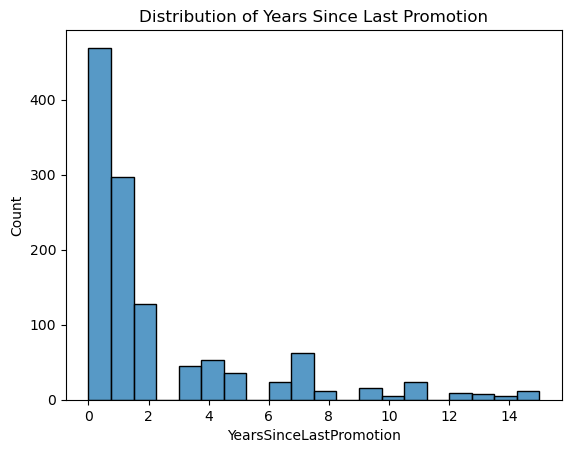

In [348]:
sns.histplot(df["YearsSinceLastPromotion"], bins=20)
plt.title("Distribution of Years Since Last Promotion")
plt.show()

In [349]:
df['YearsSinceLastPromotion'].skew()

1.9749315589155791

In [350]:
from scipy import stats
import numpy as np

numerical_data = df.select_dtypes(include="number")

z_scores = np.abs(stats.zscore(numerical_data, nan_policy="omit"))

threshold = 3

outlier_counts = (z_scores > threshold).sum(axis=0)

outlier_summary = pd.DataFrame({
    "Variable": numerical_data.columns,
    "Outlier Count": outlier_counts.values,
    "Outlier Percentage": (
        outlier_counts.values / len(df) * 100
    ).round(2)
})

display(outlier_summary)

,Variable,Outlier Count,Outlier Percentage
0,Age,0,0.00
1,DistanceFromHome,0,0.00
2,EmpHourlyRate,0,0.00
3,NumCompaniesWorked,0,0.00
4,EmpLastSalaryHikePercent,0,0.00
5,TotalWorkExperienceInYears,11,0.92
6,TrainingTimesLastYear,0,0.00
7,ExperienceYearsAtThisCompany,22,1.83
8,ExperienceYearsInCurrentRole,12,1.00
9,YearsSinceLastPromotion,33,2.75


In [351]:
df["DistanceFromHome"].nunique()


29

In [352]:
definitions = pd.read_excel(
    "../../data/raw/INX_Future_Inc_Employee_Performance_CDS_Project2_Data_V1.8.xls",
    sheet_name="Data Definitions",
    header=None
)

display(definitions)

,0,1
0,NaN,NaN
1,NaN,NaN
2,EmpEducationLevel,1 'Below College'
3,NaN,2 'College'
4,NaN,3 'Bachelor'
5,NaN,4 'Master'
6,NaN,5 'Doctor'
7,NaN,NaN
8,EmpEnvironmentSatisfaction,1 'Low'
9,NaN,2 'Medium'


In [353]:
df['PerformanceRating'].value_counts()
performance_by_department = pd.crosstab(df['EmpDepartment'], df['PerformanceRating'], normalize='index')*100

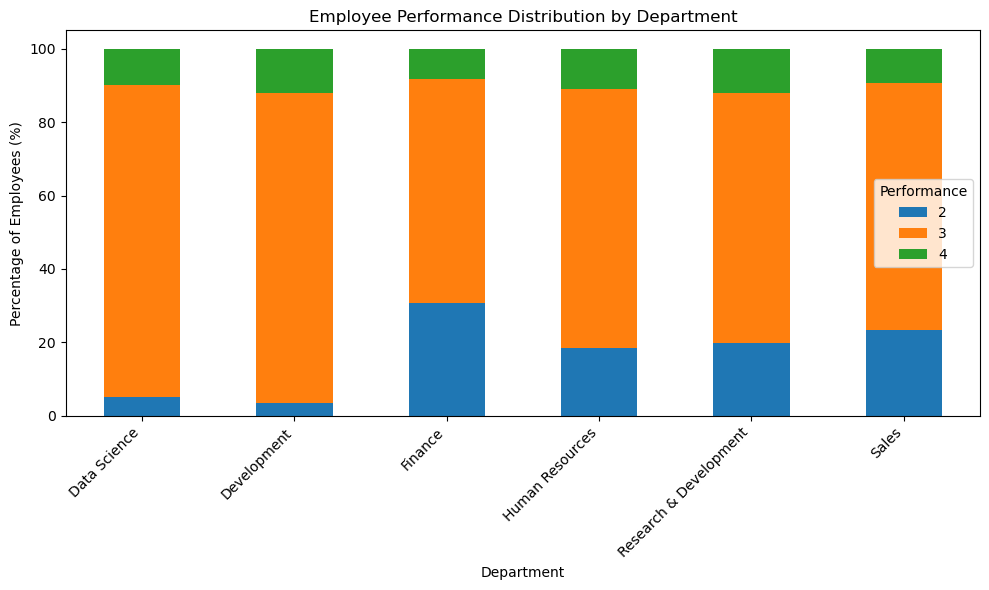

In [354]:
performance_by_department.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Employee Performance Distribution by Department')
plt.xlabel('Department')
plt.ylabel('Percentage of Employees (%)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Performance')
plt.tight_layout()
plt.show()

In [355]:

ordinal_categorical = ['EmpEducationLevel', 'EmpEnvironmentSatisfaction', 'EmpJobInvolvement', 
'EmpJobLevel', 'EmpJobSatisfaction', 'EmpRelationshipSatisfaction', 'EmpWorkLifeBalance', 'PerformanceRating']

ordinal_categorical = df[ordinal_categorical].astype('int')

travel_mapping = {"Non-Travel": 0, "Travel_Rarely": 1, "Travel_Frequently": 2}
df["BusinessTravelFrequency"] = df["BusinessTravelFrequency"].map(
    travel_mapping
)

for col in ordinal_categorical:
    df[col] = df[col].astype(int)

nominal_categorical_1 = [
"EducationBackground",
"EmpDepartment",
"EmpJobRole",
"MaritalStatus"]


nominal_categorical_2 = ["Attrition",
"Gender",
"OverTime",
]

binary_mapping = {"No": 0, "Yes": 1}
Binary_mapping = {"True": 1, "False": 0}
gender_mapping = {"Female": 0, "Male": 1}

df['Attrition'].astype('int8')
df['OverTime'].astype('int8')

df["Attrition"] = df["Attrition"].map(binary_mapping)
df["OverTime"] = df["OverTime"].map(binary_mapping)
df["Gender"] = df["Gender"].map(gender_mapping)

df["Attrition"] = df["Attrition"].fillna(0).astype("int8")
df["OverTime"] = df["OverTime"].fillna(0).astype("int8")
df["Gender"] = df["Gender"].fillna(0).astype("int8")

df = pd.get_dummies(df, columns=nominal_categorical_1, drop_first=True, dtype=int)

numerical_columns = ["Age",
    "DistanceFromHome",
    "EmpHourlyRate",
    "NumCompaniesWorked",
    "EmpLastSalaryHikePercent",
    "TotalWorkExperienceInYears",
    "TrainingTimesLastYear",
    "ExperienceYearsAtThisCompany",
    "ExperienceYearsInCurrentRole",
    "YearsSinceLastPromotion",
    "YearsWithCurrManager",
]

scaler = StandardScaler()
df[numerical_columns] = scaler.fit_transform(df[numerical_columns])


In [356]:
x = df.drop(columns=["PerformanceRating", "EmpNumber"])
y = df["PerformanceRating"]

In [357]:
print(x.isna().sum()[x.isna().sum() > 0])


Series([], dtype: int64)


In [363]:
x = df.drop(columns=["PerformanceRating", "EmpNumber"])
y = df["PerformanceRating"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(x_train, y_train)

y_pred = model.predict(x_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("Classification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[ 17  11   1]
 [ 13 168   3]
 [  0   8  19]]
Classification Report:
              precision    recall  f1-score   support

           2       0.57      0.59      0.58        29
           3       0.90      0.91      0.91       184
           4       0.83      0.70      0.76        27

    accuracy                           0.85       240
   macro avg       0.76      0.73      0.75       240
weighted avg       0.85      0.85      0.85       240



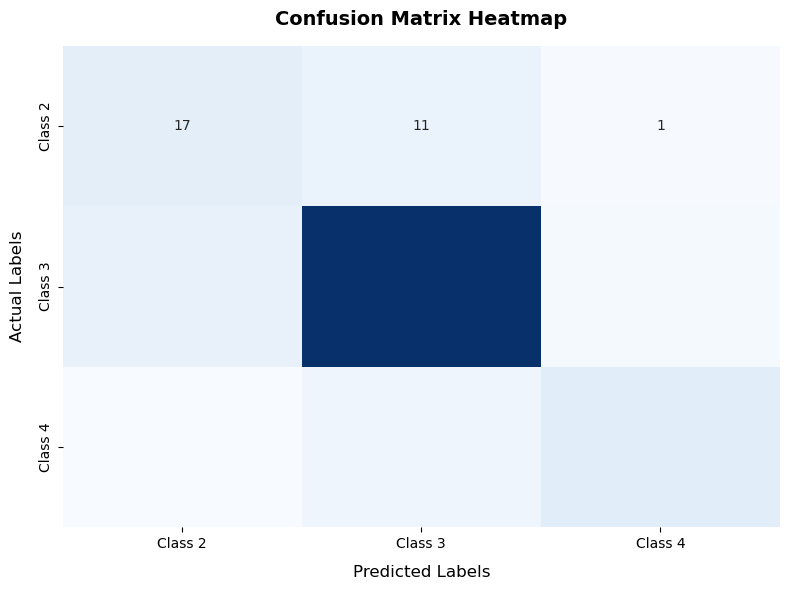

In [365]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Compute confusion matrix using your test data
cm = confusion_matrix(y_test, y_pred)

# 2. Build the visual heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Class 2", "Class 3", "Class 4"],
    yticklabels=["Class 2", "Class 3", "Class 4"],
    cbar=False,
)

# 3. Add labels and layout styling
plt.title("Confusion Matrix Heatmap", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Predicted Labels", fontsize=12, labelpad=10)
plt.ylabel("Actual Labels", fontsize=12, labelpad=10)
plt.tight_layout()

# 4. Display the plot
plt.show()


In [364]:
feature_names = x_train.columns
coefficients = model.coef_

coef_df = pd.DataFrame(coefficients, columns=feature_names, index=[f"Effect_on_Class_{c}" for c in model.classes_]).T

print("how each column affects performance rating:")
print(coef_df)

how each column affects performance rating:
                                      Effect_on_Class_2  Effect_on_Class_3  \
Age                                           -0.042661          -0.035024   
Gender                                        -0.088176           0.042785   
BusinessTravelFrequency                       -0.132356          -0.114952   
DistanceFromHome                               0.160622           0.032265   
EmpEducationLevel                             -0.230594           0.082655   
EmpEnvironmentSatisfaction                    -1.527754           0.484557   
EmpHourlyRate                                  0.109780          -0.088246   
EmpJobInvolvement                              0.021429           0.128714   
EmpJobLevel                                    0.173394          -0.160114   
EmpJobSatisfaction                            -0.047881          -0.004597   
NumCompaniesWorked                             0.040477          -0.098747   
OverTime            

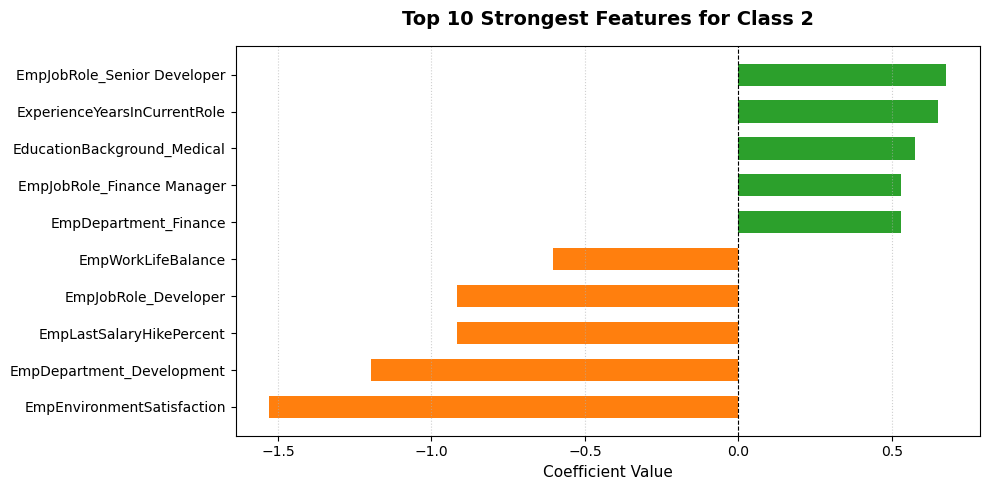

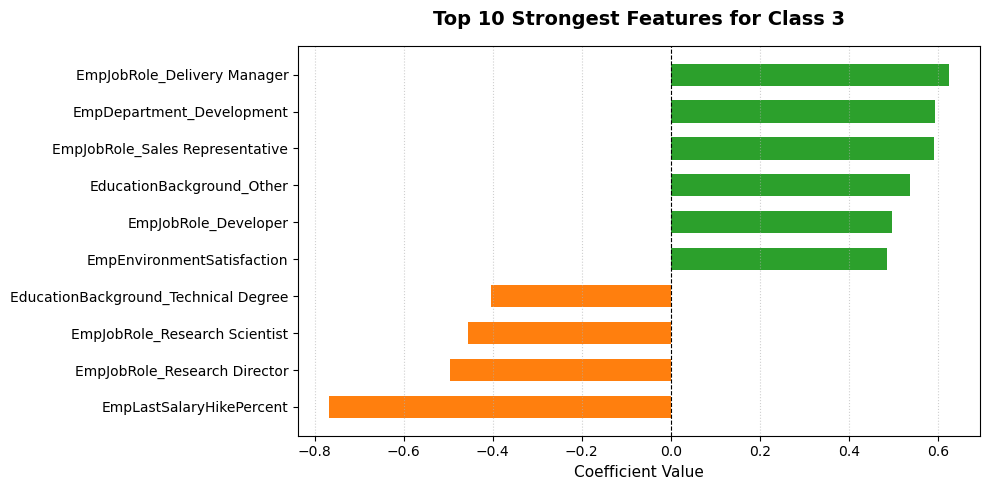

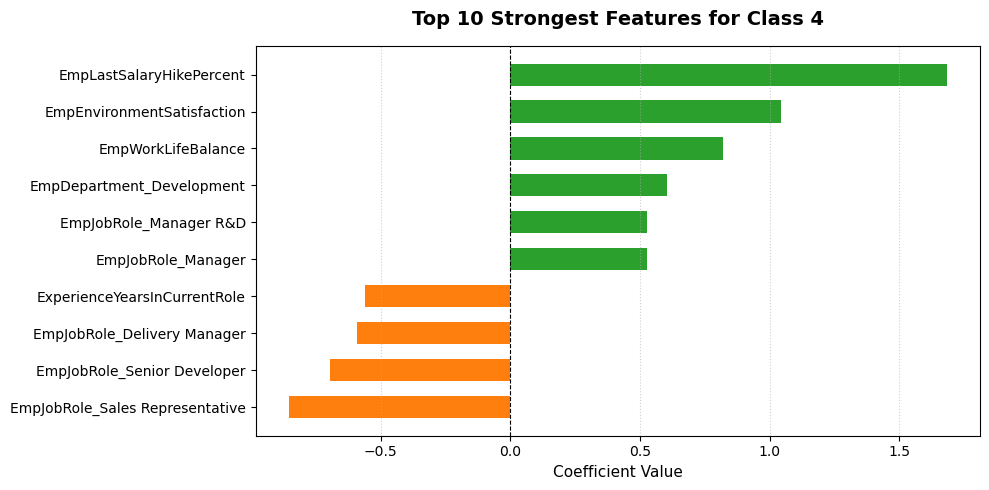

In [369]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Rebuild the dataframe
feature_names = x_train.columns
coef_df = pd.DataFrame(
    model.coef_,
    columns=feature_names,
    index=[f"Class {c}" for c in model.classes_],
).T

# 2. Plot ONLY the top 10 most impactful features per class
for target_class in coef_df.columns:
    # Sort features by absolute impact
    sorted_df = coef_df[[target_class]].copy()
    sorted_df["abs_val"] = sorted_df[target_class].abs()
    sorted_df = sorted_df.sort_values(by="abs_val", ascending=False)

    # Keep only the top 10 strongest columns (drop the zero/tiny noise)
    top_10 = sorted_df.head(10).sort_values(by=target_class, ascending=True)

    # Plotting code with ample vertical spacing
    plt.figure(figsize=(10, 5))
    colors = [
        "#2ca02c" if val >= 0 else "#ff7f0e"
        for val in top_10[target_class].values
    ]

    plt.barh(top_10.index, top_10[target_class].values, color=colors, height=0.6)
    plt.axvline(0, color="black", linestyle="--", linewidth=0.8)

    plt.title(
        f"Top 10 Strongest Features for {target_class}",
        fontsize=14,
        fontweight="bold",
        pad=15,
    )
    plt.xlabel("Coefficient Value", fontsize=11)

    # Clean adjustments to prevent overlaps
    plt.yticks(fontsize=10)
    plt.grid(axis="x", linestyle=":", alpha=0.6)
    plt.tight_layout()
    plt.show()


drop attrition and overtime